# Data Visualization with Matplotlib and Seaborn
**Month 2 - Week 1 Tasks**

Part 1: 7 Matplotlib tasks, Part 2: 7 Seaborn tasks.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic = sns.load_dataset("titanic")

# Part 1: Matplotlib Tasks

## Task 1

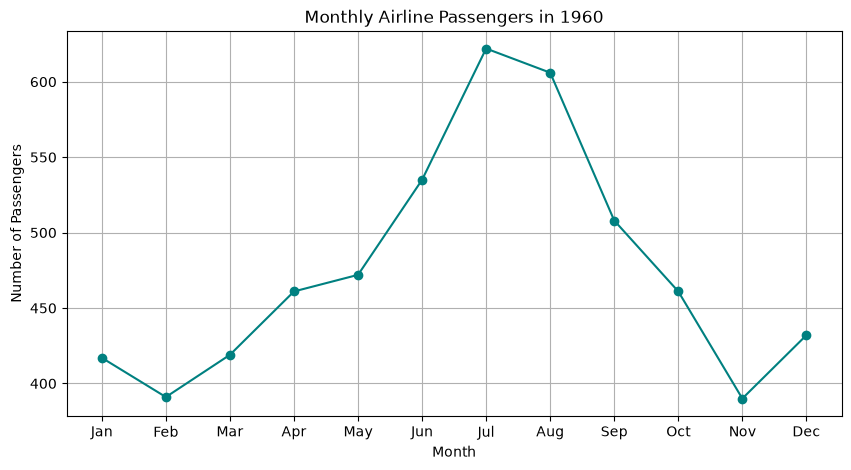

In [2]:
flights_1960 = flights[flights["year"] == 1960]

plt.figure(figsize=(10, 5))
plt.plot(flights_1960["month"].astype(str), flights_1960["passengers"], marker="o", color="teal")
plt.title("Monthly Airline Passengers in 1960")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.grid(True)
plt.show()

**What does this chart tell us?**
Passenger numbers peak in the summer months (July has the most, 622) and drop in November and February.
This shows that air travel is seasonal, with more people flying during summer holidays.

## Task 2

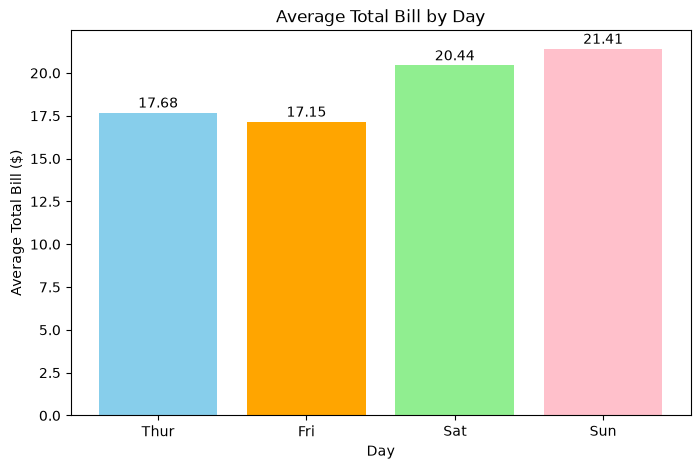

In [3]:
avg_bill = tips.groupby("day", observed=True)["total_bill"].mean()

plt.figure(figsize=(8, 5))
plt.bar(avg_bill.index.astype(str), avg_bill.values, color=["skyblue", "orange", "lightgreen", "pink"])

for i in range(len(avg_bill)):
    plt.text(i, avg_bill.values[i] + 0.3, round(avg_bill.values[i], 2), ha="center")

plt.title("Average Total Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Total Bill ($)")
plt.show()

**What does this chart tell us?**
Bills are higher on the weekend, with Sunday having the highest average bill (about $21.41).
Friday has the lowest average bill (about $17.15).

## Task 3

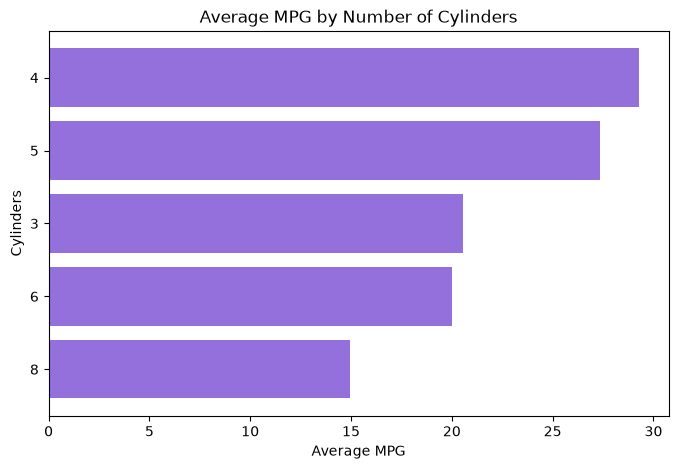

In [4]:
avg_mpg = mpg.groupby("cylinders")["mpg"].mean()

avg_mpg = avg_mpg.sort_values()

plt.figure(figsize=(8, 5))
plt.barh(avg_mpg.index.astype(str), avg_mpg.values, color="mediumpurple")
plt.title("Average MPG by Number of Cylinders")
plt.xlabel("Average MPG")
plt.ylabel("Cylinders")
plt.show()

**What does this chart tell us?**
4-cylinder cars have the best fuel efficiency (about 29.3 mpg) and 8-cylinder cars have the worst (about 15 mpg).
In general, more cylinders means lower mpg (3 and 5 cylinder cars are very few in the data, so their averages are less reliable).

## Task 4

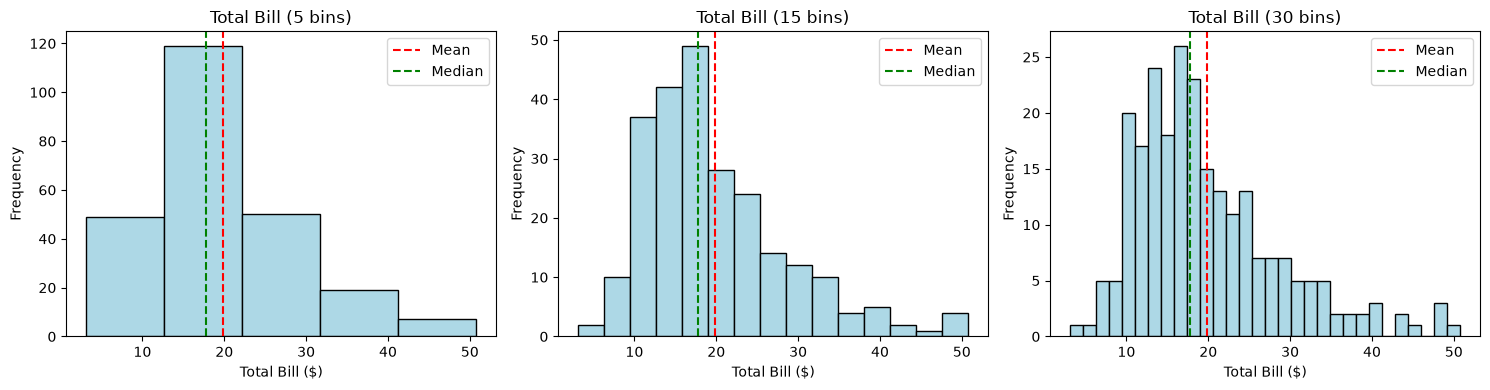

In [5]:
mean_bill = tips["total_bill"].mean()
median_bill = tips["total_bill"].median()
bin_sizes = [5, 15, 30]

plt.figure(figsize=(15, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.hist(tips["total_bill"], bins=bin_sizes[i], color="lightblue", edgecolor="black")
    plt.axvline(mean_bill, color="red", linestyle="--", label="Mean")
    plt.axvline(median_bill, color="green", linestyle="--", label="Median")
    plt.title("Total Bill (" + str(bin_sizes[i]) + " bins)")
    plt.xlabel("Total Bill ($)")
    plt.ylabel("Frequency")
    plt.legend()

plt.tight_layout()
plt.show()

**What does this chart tell us?**
Most bills are between $10 and $25, and the data is right-skewed (a few large bills).
Because of this, the mean (about $19.79) is higher than the median (about $17.80). More bins show more detail, while fewer bins show the overall shape.

## Task 5

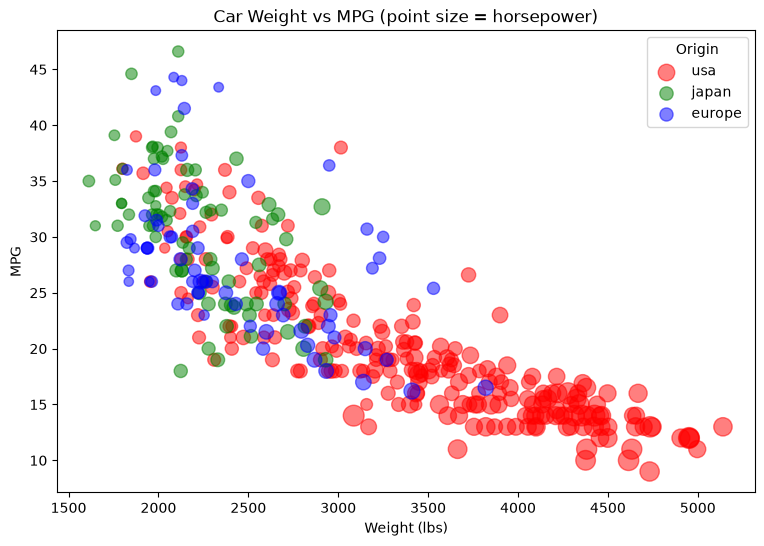

In [6]:
mpg_clean = mpg.dropna()
colors = {"usa": "red", "europe": "blue", "japan": "green"}

plt.figure(figsize=(9, 6))

for origin in mpg_clean["origin"].unique():
    data = mpg_clean[mpg_clean["origin"] == origin]
    plt.scatter(data["weight"], data["mpg"], s=data["horsepower"], color=colors[origin], alpha=0.5, label=origin)

plt.title("Car Weight vs MPG (point size = horsepower)")
plt.xlabel("Weight (lbs)")
plt.ylabel("MPG")
plt.legend(title="Origin")
plt.show()

**What does this chart tell us?**
Heavier cars get lower mpg, and heavier cars also tend to have more horsepower (bigger points).
Most heavy, powerful cars are from the USA, while Japanese and European cars are lighter and more fuel efficient.

## Task 6

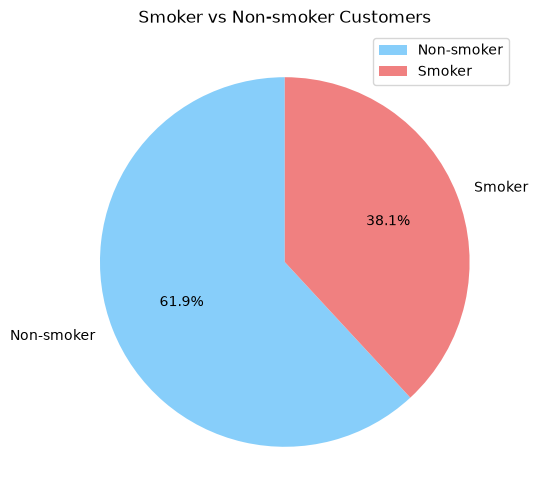

In [7]:
smoker_counts = tips["smoker"].value_counts()
labels = ["Smoker" if x == "Yes" else "Non-smoker" for x in smoker_counts.index]

plt.figure(figsize=(6, 6))
plt.pie(smoker_counts.values, labels=labels, autopct="%1.1f%%", colors=["lightskyblue", "lightcoral"], startangle=90)
plt.title("Smoker vs Non-smoker Customers")
plt.legend()
plt.show()

**What does this chart tell us?**
About 62% of the customers are non-smokers and about 38% are smokers.
So the majority of tables in this restaurant are non-smoking.

## Task 7

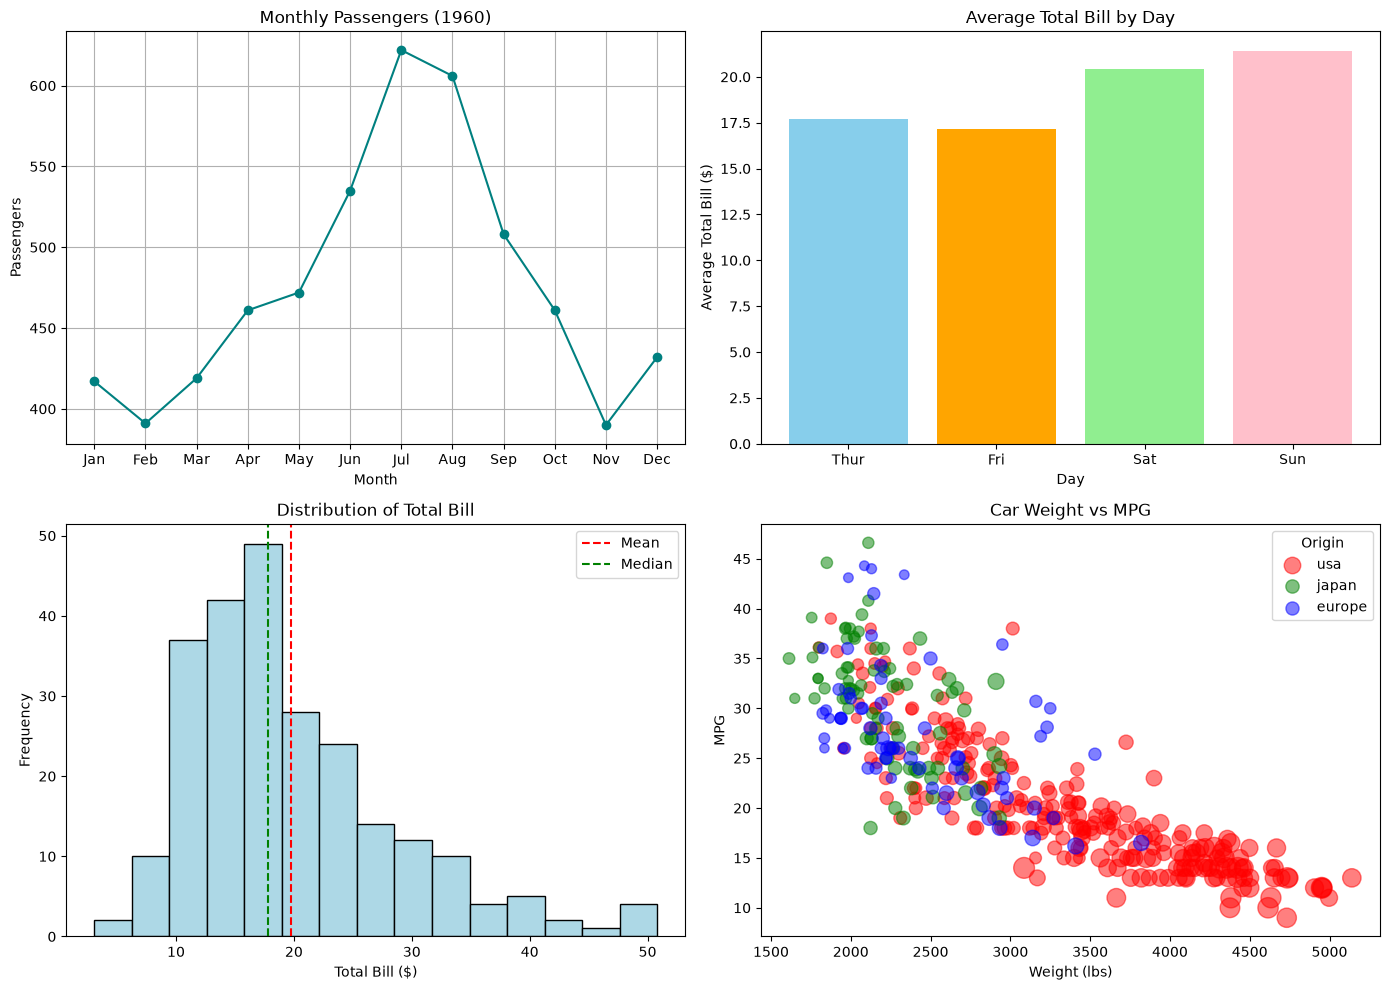

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(flights_1960["month"].astype(str), flights_1960["passengers"], marker="o", color="teal")
axes[0, 0].set_title("Monthly Passengers (1960)")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Passengers")
axes[0, 0].grid(True)

axes[0, 1].bar(avg_bill.index.astype(str), avg_bill.values, color=["skyblue", "orange", "lightgreen", "pink"])
axes[0, 1].set_title("Average Total Bill by Day")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Average Total Bill ($)")

axes[1, 0].hist(tips["total_bill"], bins=15, color="lightblue", edgecolor="black")
axes[1, 0].axvline(mean_bill, color="red", linestyle="--", label="Mean")
axes[1, 0].axvline(median_bill, color="green", linestyle="--", label="Median")
axes[1, 0].set_title("Distribution of Total Bill")
axes[1, 0].set_xlabel("Total Bill ($)")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

for origin in mpg_clean["origin"].unique():
    data = mpg_clean[mpg_clean["origin"] == origin]
    axes[1, 1].scatter(data["weight"], data["mpg"], s=data["horsepower"], color=colors[origin], alpha=0.5, label=origin)
axes[1, 1].set_title("Car Weight vs MPG")
axes[1, 1].set_xlabel("Weight (lbs)")
axes[1, 1].set_ylabel("MPG")
axes[1, 1].legend(title="Origin")

plt.tight_layout()
plt.savefig("matplotlib_dashboard.png", dpi=300)
plt.show()

**What does this chart tell us?**
Putting the plots together gives a quick summary: air travel is seasonal, weekend bills are higher, most bills are under $25, and heavier cars use more fuel.
The dashboard is saved as `matplotlib_dashboard.png`.

# Part 2: Seaborn Tasks

## Task 1

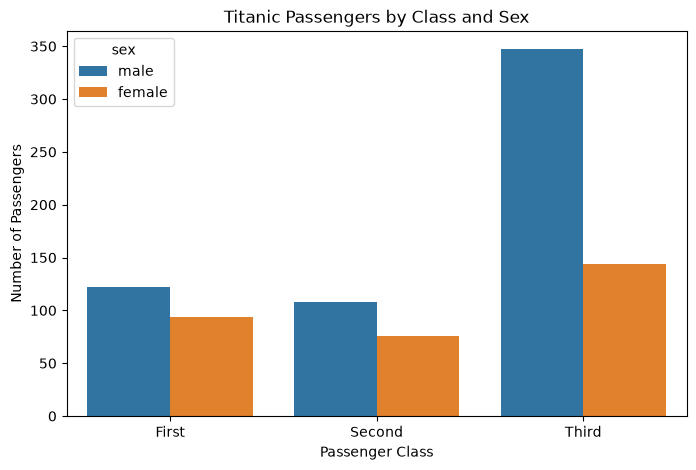

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(data=titanic, x="class", hue="sex")
plt.title("Titanic Passengers by Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

**What does this chart tell us?**
Third class had by far the most passengers, especially men (347 males).
In every class there were more male passengers than female passengers.

## Task 2

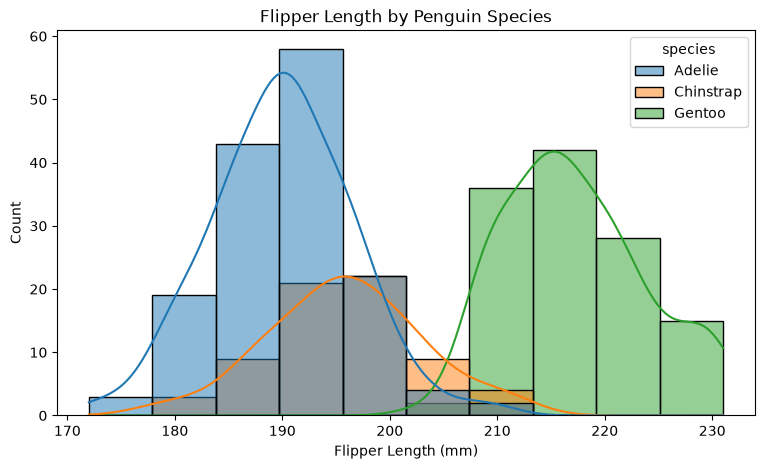

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", kde=True)
plt.title("Flipper Length by Penguin Species")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Count")
plt.show()

**What does this chart tell us?**
Gentoo penguins have clearly longer flippers (around 217 mm on average) than the other two species.
Adelie and Chinstrap flipper lengths overlap a lot (around 190-196 mm), so flipper length alone cannot separate them.

## Task 3

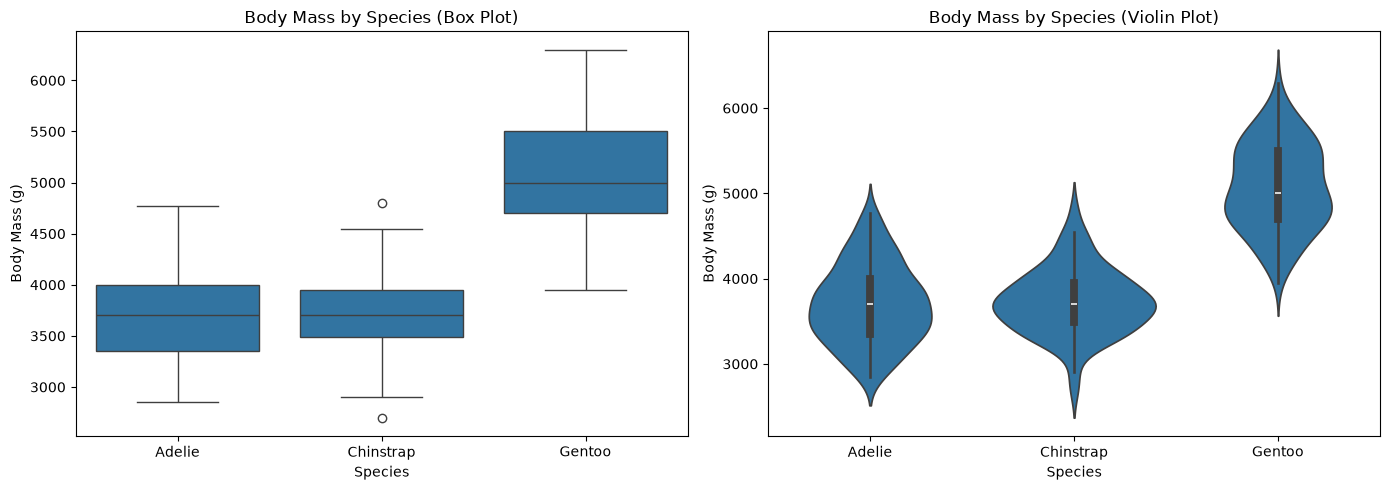

In [11]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=penguins, x="species", y="body_mass_g")
plt.title("Body Mass by Species (Box Plot)")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")

plt.subplot(1, 2, 2)
sns.violinplot(data=penguins, x="species", y="body_mass_g")
plt.title("Body Mass by Species (Violin Plot)")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")

plt.tight_layout()
plt.show()

**What does this chart tell us?**
Both plots show that Gentoo penguins are the heaviest, while Adelie and Chinstrap have similar body mass.

**Which one shows more?**
The violin plot shows more, because it shows the full shape of the distribution (where values are most common).
The box plot only shows the median, quartiles and outliers, but it is simpler and easier to read quickly.

## Task 4

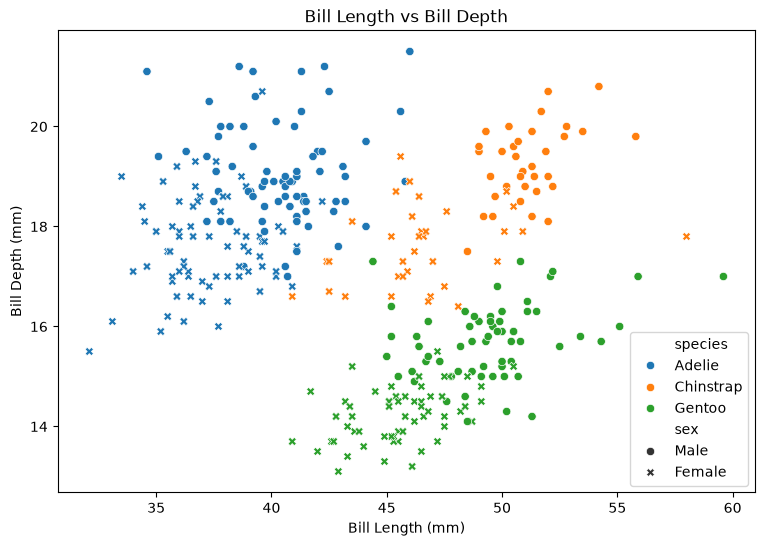

In [12]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species", style="sex")
plt.title("Bill Length vs Bill Depth")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.show()

**What does this chart tell us?**
The three species form clear separate groups: Adelie have short, deep bills, Gentoo have long, shallow bills, and Chinstrap have long, deep bills.
Within each species, males usually have bigger bills than females.

## Task 5

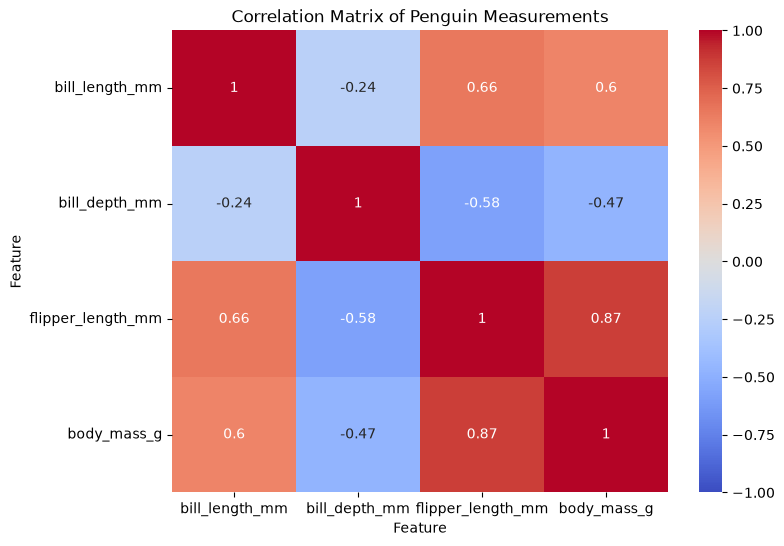

In [13]:
numeric_cols = penguins[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
corr = numeric_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Penguin Measurements")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.show()

**What does this chart tell us?**
Flipper length and body mass have a very strong positive correlation (0.87), so penguins with longer flippers are usually heavier.
Bill depth is negatively correlated with flipper length and body mass, which is mostly because Gentoo penguins are big but have shallow bills.

## Task 6

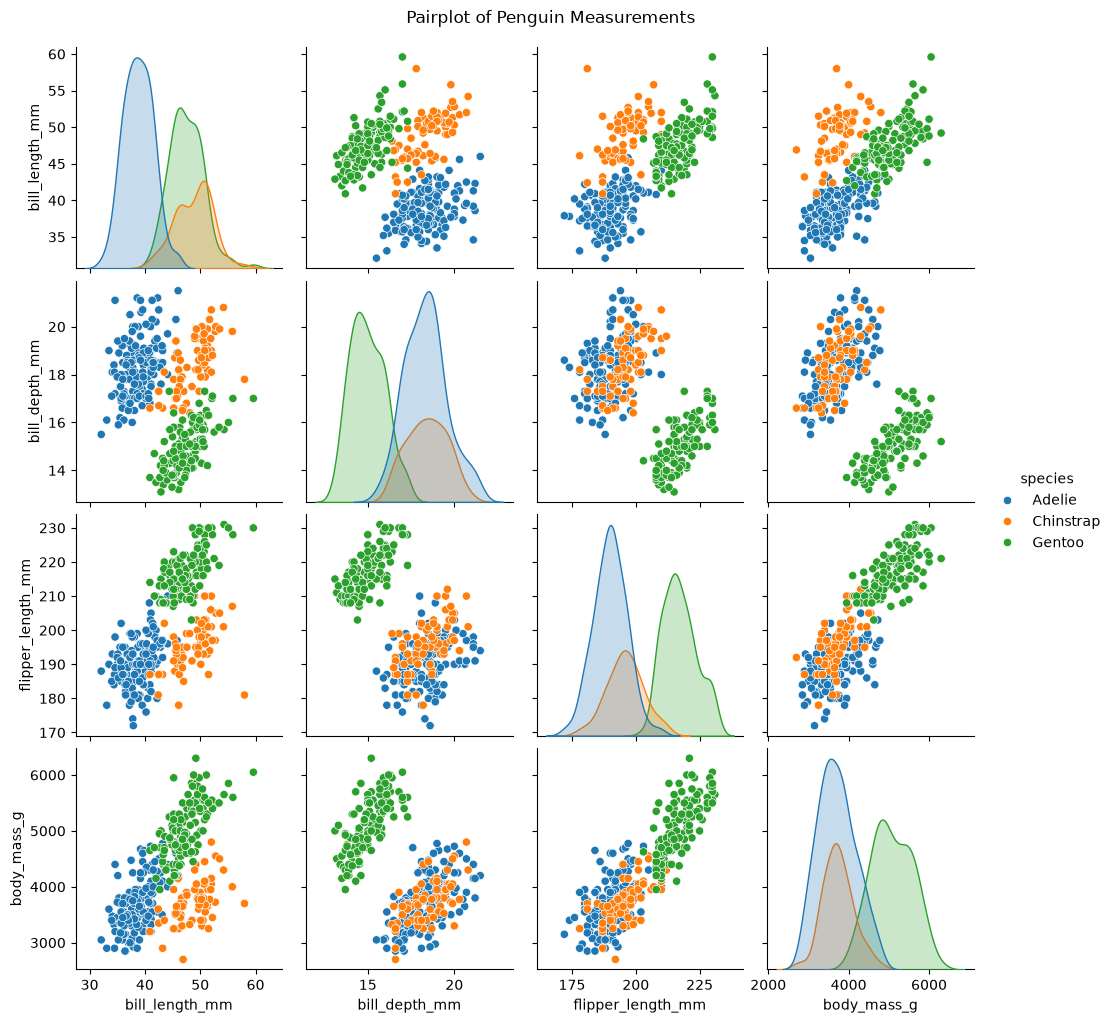

In [14]:
sns.pairplot(penguins, hue="species")
plt.suptitle("Pairplot of Penguin Measurements", y=1.02)
plt.show()

**What does this chart tell us? (3 insights)**
1. Gentoo penguins are clearly separated from the others in almost every plot, because they are bigger with longer flippers and shallower bills.
2. Flipper length and body mass have a strong straight-line (positive) relationship for all species.
3. Adelie and Chinstrap overlap in most features, but bill length separates them well (Chinstrap bills are much longer).

## Task 7

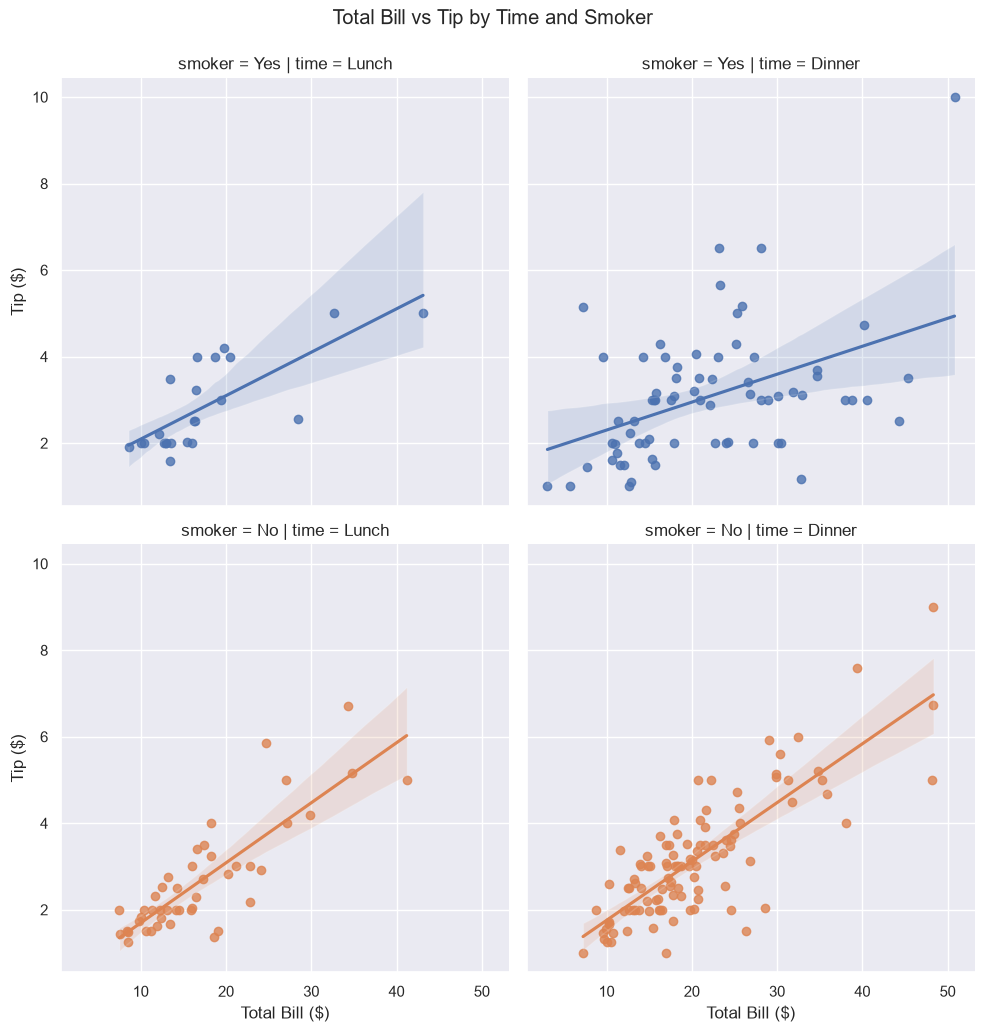

In [15]:
sns.set_theme(style="darkgrid", palette="deep")

g = sns.lmplot(data=tips, x="total_bill", y="tip", col="time", row="smoker", hue="smoker")
g.set_axis_labels("Total Bill ($)", "Tip ($)")
plt.suptitle("Total Bill vs Tip by Time and Smoker", y=1.03)
plt.show()

**What does this chart tell us?**
In every group, the tip goes up as the total bill goes up.
The relationship is weakest for smokers at dinner (their points are more spread out), while non-smokers tip more consistently with the bill size.